# O que é estatística

É uma parte da matemática em que se investigam os processos de obtenção, organização e análise de dados sobre uma população ou sobre uma coleção de setes quaisquer, e os métodos de tirar conclusões e fazer predições com base nesses dados.

Trata-se, portanto de uma metodologia desenvolvida para a coleta, classificação, apresentação, análise e interpretação de dados quantitativos e a utilização desses dados para a tomada de decisões(Toledo;Ovalle, 1995)

## Estatística descritiva

é um número que, sozinho descreve uma caracteristica de um conjunto de dados, ou seja, é um número-resumo que possibilita reduzir os dados a proporções mais facilmente interpretáveis (Toledo; Ovalle, 1995)

## Estatística indutiva, ou inferência estatística

é o processo pelo qual se admite que os resultados obtidos na análise dos dados de uma amostra são válidos para toda a população da qual aquela amostra foi retirada.

# Fases do método estatístico (estatística descritiva)

- Definição do problema
- Delimitação do problema
- Planejamento para obtenção dos dados
- Coleta dos dados
- Apuração dos dados
- Apresentação dos dados
- Análise dos dados
- Interpretação dos dados

# **Desafio #01**
Diferença entre **População vs. Amostra** e **Estatística Descritiva vs. Inferêncial(indutiva)**

**Cenário de Negócio:** e-commerce com uma **população** de 10.000 pedidos no mês. A diretoria quer saber o ticket médio, mas suponha que, para uma auditoria de qualidade, só seja possível inspecionar uma **amostra** de 150 pedidos.

## Definição do problema:
Estimar sobre 10.000 mil pedidos o ticket médio no mês de Novembro/2026 com 150 pedidos. 

### Gerar 10.000 mil pedidos usando np.random.normal

In [5]:
# Importar bibliotecas
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
# utiliza np.random para gerar 10.000 mil pedidos 
SEED = 42 # A semente garante que qualquer pessoa que rodar o código obtenha extamente os mesmos números.
N_PEDIDOS = 10_000
TICKET_MEDIO_ALVO = 150.00
DESVIO_PADRAO_ALVO = 80.00


# Conversão de reais(R$) para a escala logarítmica exigida pela "lognormal"
# Converte a média(150) e o desvio padrão(80) da escala monetária real (R$) para s \(\mu \) e \(\sigma \) de uma distribuição normal subjacente.
sigma_log = np.sqrt(np.log1p((DESVIO_PADRAO_ALVO / TICKET_MEDIO_ALVO) ** 2)) # desvio padrão populacional dividido pelo ticket médio elevado a 2
mu_log = np.log(TICKET_MEDIO_ALVO) - (sigma_log ** 2 / 2) # ticket médio - resultado de sigma_log elevado a 2 e dividido por 2


# Geração da população sintética
rng = np.random.default_rng(SEED) # Antiga np.random.seed
valores = rng.lognormal(mean=mu_log, sigma=sigma_log, size=N_PEDIDOS)


# Estruturação da tabela(DataFrame)
df_pedidos = pd.DataFrame({
    "pedido_id": np.arange(1, N_PEDIDOS + 1), # cria coluna de id_pedidos, utiliza np.arange() 1: inicia, N_PEDIDOS:finaliza + 1
    "valor_pedido": np.round(valores, 2) # arredondada para 2 casas decimais
})


# Sanity Check: valia integridade antes de qualquer análise

# assert len() verifica se a tabela tem exatamente 10.000 linhas
assert len(df_pedidos) == N_PEDIDOS, "Quantidade de pedidos divergente do esperado"
assert(df_pedidos["valor_pedido"] > 0). all(), "Existem pedidos com valor zerado ou negativo"

# Exibe o resultado na tela
print(f"População gerada com sucesso: {len(df_pedidos):,} pedidos.\n")
print(df_pedidos["valor_pedido"].describe().round(2))

População gerada com sucesso: 10,000 pedidos.

count    10000.00
mean       149.48
std         80.50
min         14.72
25%         94.31
50%        131.49
75%        183.22
max        991.97
Name: valor_pedido, dtype: float64


### Visualizar resultado em gráfico
**Boxplot:** resume os dados em blocos de 25% mas esconde o formato da curva(não vê se há um ou dois picos de vendas).

**Histograma:** mostra a frequência real dos valores, mas dificulta saber exatamente onde está o corte dos 25 ou 75% sem marcações extras.

Empilhar o **Boxplot** acima do **Histograma** compartilhando o mesmo eixo x (o valor em R$)

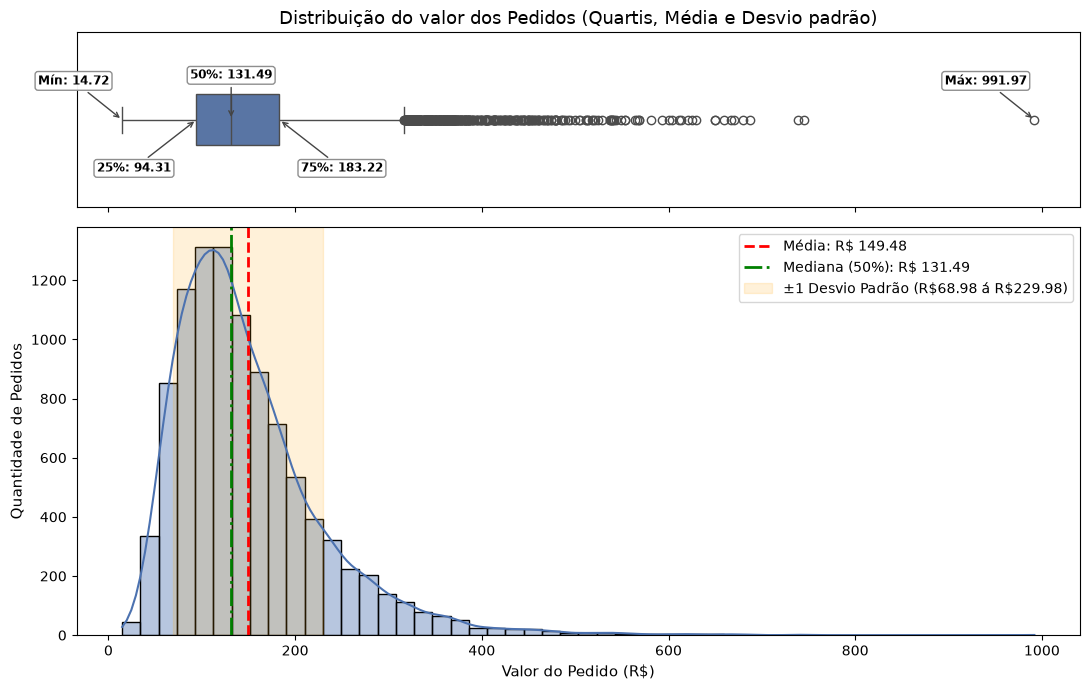

In [14]:
# Calcula as métricas reais da população
s = df_pedidos["valor_pedido"]
media = s.mean()
desvio_padrao = s.std()
v_min, q25, q50, q75, v_max = s.min(), s.quantile(0.25), s.median(), s.quantile(0.75), s.max()

# Cria uma figura com 2 painéis empilhados compartilhando o eixo x
fig, (ax_box, ax_hist) = plt.subplots(
    nrows=2,
    sharex=True,
    figsize=(11, 7),
    gridspec_kw={"height_ratios": (0.30, 0.70)} # Boxplot fino em cima, histograma maior em baixo
)

# =============================================
# Boxplot (Quartis, Mínimo, Máximo e Outliers)
# =============================================
sns.boxplot(
    x=s, 
    ax=ax_box, 
    color="#4C72B0",
    width=0.35
)
ax_box.set(xlabel="", yticks=[]) # Remove rótulo duplicado do eixo x
ax_box.set_ylim(-0.6, 0.6) # Abre espaço vertical em cima e em baixo da caixa
ax_box.set_title("Distribuição do valor dos Pedidos (Quartis, Média e Desvio padrão)", fontsize=13)

# Anotações com setas para evitar sobreposição entre 25%, 50%, e 75%
# Adiciona os rótulos numéricos diretamente no Boxplot
anotacoes = [
    (v_min, f"Mín: {v_min:.2f}",  (-35,  28)),
    (q25,   f"25%: {q25:.2f}",    (-45, -35)),
    (q50,   f"50%: {q50:.2f}",    (  0,  32)),
    (q75,   f"75%: {q75:.2f}",    ( 45, -35)),
    (v_max, f"Máx: {v_max:.2f}",  (-35,  28)),

]

for valor, texto, offset in anotacoes:
    ax_box.annotate(
        texto,
        xy=(valor, 0),
        xytext=offset,
        textcoords="offset points",
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#888888", alpha=0.95),
        arrowprops=dict(arrowstyle="->", color="#444444", lw=1)
        
    )

# ===========================================
# Histograma + Curva de Densidade
# ===========================================
sns.histplot(s, bins=50, kde=True, ax=ax_hist, color="#4C72B0", alpha=0.4)

# Linhas verticais para média, Mediana e Desvio padrão
ax_hist.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Média: R\\$ {media:.2f}")
ax_hist.axvline(q50, color="green", linestyle="-.", linewidth=2, label=f"Mediana (50%): R\\$ {q50:.2f}")


# Faixa sombreada representando 1 desvio padrão (Média ± Desvio Padrão)
limite_inf = max(0, media - desvio_padrao)
limite_sup = media + desvio_padrao

ax_hist.axvspan(
    limite_inf, 
    limite_sup,
    color="orange",
    alpha=0.15,
    # Uso de R\\$ (com barra invertida) evita que o Matplotlib ative o modo matemático LaTex
    label=f"±1 Desvio Padrão (R\\${limite_inf:.2f} á R\\${limite_sup:.2f})"
)

ax_hist.set_xlabel("Valor do Pedido (R$)", fontsize=11)
ax_hist.set_ylabel("Quantidade de Pedidos", fontsize=11)
ax_hist.legend()

plt.tight_layout()
plt.show()

## Como ler o resultado
**Boxplot(topo):** 
- A borda esquerda marca R$94,31 (25%), 
- O traço interno marca R$131,49 (50% ou Mediana),
- A borda direita marca R$183,22 (75%),
- Mín é o valor mínimo R$14,72,
- Máx é o valor máximo R$997,97.

Os pontinhos espalhados à direita até R$991,97 mostram visualmente a cauda longa puxando a média para cima.

- **Histograma(base):** 
- A linha vermelha da Média R$ 149,48 fica à direita da linha verde da Mediana R$131,49 ou seja Média > Mediana = distribuição assimétrica positiva (ou assimétrica à direita) 
- assinatura clássica de dados financeiros assimétricos.

# **Simular inferência**

In [16]:
# Parâmetros dinâmicos do DataFrame
media_populacional = df_pedidos["valor_pedido"].mean()
TAMANHO_AMOSTRA = 150        # amostra para auditoria
SEEDS_AMOSTRA = [10, 20, 30] # cada número vai representar o sorteio independente de um auditor diferente

# Cria uma lista vazia para acumular os resultados de cada volta
resultados = []

# Extrai múltiplas amostras sem reposição e mede o erro em relação à média populacional.
for i, seed in enumerate(SEEDS_AMOSTRA, start=1):
    amostra = df_pedidos["valor_pedido"].sample(
        n=TAMANHO_AMOSTRA,
        replace=False, # sorteia sem repetição
        random_state=seed
    )
    media_amostral = amostra.mean()
    erro_absoluto = media_amostral - media_populacional
    erro_percentual = (erro_absoluto / media_populacional) * 100

    # Dicionário com as chaves para guardar os nomes das colunas da tabela
    resultados.append({
        "Amostra": f"Amostra{i}",
        "Seed": seed,
        "Média Populacional":  round(media_populacional, 2),
        "Média Amostral":      round(media_amostral, 2),
        "Erro Absoluto":       round(erro_absoluto, 2),
        "Erro Percentual":     round(erro_percentual, 2)
    })

# Transforma a lista de dicionário em um DataFrame
df_resumo = pd.DataFrame(resultados)

df_resumo

,Amostra,Seed,Média Populacional,Média Amostral,Erro Absoluto,Erro Percentual
0,Amostra1,10,149.48,143.89,-5.59,-3.74
1,Amostra2,20,149.48,136.99,-12.49,-8.35
2,Amostra3,30,149.48,147.51,-1.96,-1.31


## Pergunta de negócio:
Estimar o ticket médio de Nov/2026 com 150 pedidos 

## O que foi feito: 
Simulação de uma população de 10.000 pedidos (distribuição lognormal) e extração de 3 amostras independentes de 150 pedidos sem reposição.

## O que foi investigado: 
Comportamento da distribuição (assimétrica positiva, onde a média é puxada pela cauda longa) e o impacto da variabilidade amostral no erro de estimação.

# Recomendação: 
O que os números provaram (erros variando de -1,31% a -8,35% apenas pelo acaso do sorteio), não apresentar uma média amostral isolada sem informar a margem de incerteza ou avaliar o tamanho da amostra.